### Apriori

In [1]:
import pandas as pd

data = pd.read_csv('bank_prod_order.csv',encoding='gbk')
data.head()

,OrderNumber,CSR_ID,PROD
0,0,30924038,抵押贷
1,1,30924038,黄金1号
2,2,30924038,网银
3,2,30924038,想分就分
4,4,30924062,pos贷


In [2]:
baskets = data['PROD'].groupby(data['CSR_ID']).apply(list)
baskets.head()

CSR_ID
335380                      [加速积分]
337320                       [好享贷]
339311    [财务通, 好享贷, 基金, 手机银行, 网银]
351538                       [好享贷]
367537                   [好享贷, 网银]
Name: PROD, dtype: object

In [3]:
import sys
sys.path.append('./myscript')
from apriori import arules

rules = arules(baskets, min_support=0.02)
rules.head()

apriori imported!


,LHS,RHS,support,confidence,lift
0,(网银),(基金),0.054167,0.076321,1.169172
1,(基金),(网银),0.054167,0.829787,1.169172
2,(好享贷),(财务通),0.062500,0.100223,0.820004
3,(财务通),(好享贷),0.062500,0.511364,0.820004
4,(好享贷),(手机银行),0.145833,0.233853,0.956671


可以根据需要进行后续处理，例如按照confidence和lift过滤后，按support排序

In [4]:
conf = rules[(rules.confidence > 0.1) & (rules.lift > 1)]
conf.sort_values(by='support', ascending=False).head()

,LHS,RHS,support,confidence,lift
12,(手机银行),(网银),0.2000,0.818182,1.152820
13,(网银),(手机银行),0.2000,0.281800,1.152820
125,(手机银行),"(好享贷, 网银)",0.1125,0.460227,1.090012
126,(网银),"(好享贷, 手机银行)",0.1125,0.158513,1.086944
127,"(好享贷, 手机银行)",(网银),0.1125,0.771429,1.086944


如果有必要，我们也可以通过图形看一下规则在支持度、置信度和提升度上的分布情况

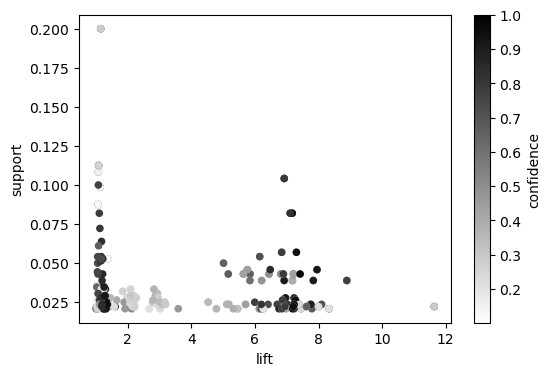

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

ax = plt.subplot()
ax.set_xlabel('lift')
conf.plot.scatter(x="lift", y="support",c="confidence",cmap='binary',
                  figsize=(6,4), ax=ax)

plt.show()

### FP_growth

`pip install Orange3-Associate` first!

[参考文档](https://orange3-associate.readthedocs.io/en/latest/scripting.html)

In [6]:
mapping = data['PROD'].drop_duplicates().to_dict()  # 生成{编号:产品}映射
inverse_mapping = {v:k for k, v in mapping.items()}     # 生成{产品:编号}映射

data['PROD'] = data['PROD'].replace(inverse_mapping)  # 将产品用编号替代
baskets = data['PROD'].groupby(data['CSR_ID']).apply(list)  
baskets.head()

C:\Users\admin\AppData\Local\Temp\1\ipykernel_5320\493410708.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['PROD'] = data['PROD'].replace(inverse_mapping)  # 将产品用编号替代


CSR_ID
335380                  [29]
337320                  [16]
339311    [14, 16, 18, 9, 2]
351538                  [16]
367537               [16, 2]
Name: PROD, dtype: object

In [7]:
from orangecontrib.associate.fpgrowth import *  

# 计算关联规则
n_examples=len(data)
itemsets = dict(frequent_itemsets(baskets.tolist(), 0.02))
rules = association_rules(itemsets, min_confidence=0.1)
stats = rules_stats(rules, itemsets, n_examples)

result = pd.DataFrame(stats, columns=['atecedent', 'consequent', 'support', 
                                      'confidence', 'coverage', 'strength', 
                                      'lift', 'leverage'])

# 将整型的项转换为原始产品名称
pid_to_product = lambda fsets: tuple(mapping[fset] for fset in fsets)
result['atecedent'] = result['atecedent'].map(pid_to_product)
result['consequent'] = result['consequent'].map(pid_to_product)
result.head()

,atecedent,consequent,support,confidence,coverage,strength,lift,leverage
0,"(手机银行, 网银, 外汇保)","(黄金1号,)",15,0.789474,0.009927,4.368421,18.205453,0.007407
1,"(黄金1号, 手机银行, 外汇保)","(网银,)",15,0.882353,0.008882,30.058824,3.304938,0.005466
2,"(手机银行, 外汇保)","(黄金1号, 网银)",15,0.681818,0.011494,2.863636,20.714286,0.007459
3,"(黄金1号, 网银, 外汇保)","(手机银行,)",15,0.254237,0.030825,2.983051,2.764831,0.005002
4,"(网银, 外汇保)","(手机银行, 黄金1号)",15,0.208333,0.037618,0.250000,22.152778,0.007483


- atecedent (frozenset) – The LHS of the association rule.
- consequent (frozenset) – The RHS of the association rule.
- support (int) – Support as an absolute number of instances.
- confidence (float) – The confidence percent, calculated as: total_support / lhs_rupport.
- coverage (float) – Calculated as: lhs_support / n_examples
- strength (float) – Calculated as: rhs_support / lhs_examples
- lift (float) – Calculated as: n_examples * total_support / lhs_support / rhs_support
- leverage (float) – Calculated as: (total_support * n_examples - lhs_support * rhs_support) / n_examples**2